# Notebook 03: Análisis Exploratorio de Datos (EDA)
**Proyecto:** Predicción de Insatisfacción del Cliente — Olist (Grupo C)

Se analiza `base_consolidada.csv` (Notebook 02): una fila por pedido entregado con reseña.

**Pasos:**
1. Clasificación de variables y diccionario.
2. Variable objetivo y desbalance.
3. Análisis univariado (numéricas, categóricas y binarias).
4. Relación de cada predictora con la insatisfacción.
5. Correlaciones y conclusiones.

Los gráficos se guardan en `informe/figuras/` para el informe.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

sys.path.append(os.path.abspath('../src'))
from preparacion import leer_base, tasa_insatisfaccion
from variables import (VARS_REFERENCIA, VAR_OBJETIVO, VARS_FUGA, VARS_BINARIAS,
                       VARS_CATEGORICAS, VARS_NUMERICAS, DESCRIPCION)
from utils import resumen_numerico, tabla_outliers

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_colwidth', 70)

RUTA_FIG = '../informe/figuras'
os.makedirs(RUTA_FIG, exist_ok=True)

# Colores fijos para todo el informe: azul = satisfecho, naranja = insatisfecho
AZUL, NARANJA = '#2a78d6', '#eb6834'

# Estilo uniforme para todos los gráficos (fondo blanco para el PDF)
pio.templates['grupo_c'] = go.layout.Template(layout=dict(
    font=dict(family='Arial', size=13, color='#0b0b0b'),
    paper_bgcolor='white', plot_bgcolor='white',
    title=dict(x=0.5, font=dict(size=16)),
    xaxis=dict(showgrid=False, linecolor='#52514e', ticks='outside'),
    yaxis=dict(gridcolor='#e6e5e1', linecolor='#52514e', zeroline=False),
    margin=dict(l=60, r=30, t=70, b=50),
))
pio.templates.default = 'plotly_white+grupo_c'

# Interactivo en VS Code + imagen estática para que se vea en GitHub
pio.renderers.default = 'vscode+png'

def guardar(fig, nombre):
    """Guarda la figura como PNG en informe/figuras para usarla en el PDF."""
    fig.write_image(os.path.join(RUTA_FIG, nombre + '.png'), scale=2)

df = leer_base('../data/procesado/base_consolidada.csv')
print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')

Filas: 95,603 | Columnas: 57


## 1. Clasificación de las variables
| Grupo | Uso |
|---|---|
| Referencia | Identificadores, fechas originales y controles de calidad. No se analizan ni se usan en el modelo |
| Objetivo | `insatisfecho`: lo que se predice |
| Reseña y entrega real (no predictoras) | Datos de la encuesta y días reales de entrega/atraso. Se usan en el EDA para entender el problema, pero **no en el modelo**: se conocen después del momento en que el modelo tiene que predecir |
| Binarias, categóricas y numéricas | Predictoras: se analizan en el EDA y se usan en el modelo |

La clasificación está en `src/variables.py` para usarla igual en todos los notebooks.

In [2]:
grupos = {
    'referencia (no predictoras)': VARS_REFERENCIA,
    'objetivo': [VAR_OBJETIVO],
    'información posterior (solo EDA)': VARS_FUGA,
    'binarias': VARS_BINARIAS,
    'categóricas': VARS_CATEGORICAS,
    'numéricas': VARS_NUMERICAS,
}
display(pd.DataFrame({'cantidad de variables': {g: len(v) for g, v in grupos.items()}}))

# Control: todas las columnas de la base deben estar clasificadas, y ninguna de más
clasificadas = sum(grupos.values(), [])
sin_clasificar = set(df.columns) - set(clasificadas)
inexistentes = set(clasificadas) - set(df.columns)

print(f'Clasificadas: {len(clasificadas)} de {df.shape[1]} columnas')
print('✔ Todas las columnas están clasificadas' if not sin_clasificar
      else f'✘ Columnas sin clasificar: {sin_clasificar}')
print('✔ No hay nombres inexistentes en variables.py' if not inexistentes
      else f'✘ Nombres que no existen en la base: {inexistentes}')

,cantidad de variables
referencia (no predictoras),15
objetivo,1
información posterior (solo EDA),7
binarias,4
categóricas,8
numéricas,22


Clasificadas: 57 de 57 columnas
✔ Todas las columnas están clasificadas
✔ No hay nombres inexistentes en variables.py


## 2. Diccionario de variables
Descripción, tipo, porcentaje de nulos y cantidad de valores únicos de cada variable analizable.

In [3]:
rol = {v: g for g, lista in grupos.items() for v in lista}

diccionario = pd.DataFrame([{
    'variable': v,
    'grupo': rol[v],
    'descripción': d,
    'tipo': str(df[v].dtype),
    '% nulos': round(df[v].isna().mean() * 100, 2),
    'valores únicos': df[v].nunique(),
} for v, d in DESCRIPCION.items()]).set_index('variable')

# Una tabla por grupo, para que se lea más fácil
for grupo, tabla in diccionario.groupby('grupo', sort=False):
    print(f'\n■ {grupo.upper()} ({len(tabla)} variables)')
    display(tabla.drop(columns='grupo'))
    
diccionario.to_csv('../data/procesado/diccionario_variables.csv')


■ OBJETIVO (1 variables)


,descripción,tipo,% nulos,valores únicos
variable,,,,
insatisfecho,"Variable objetivo: 1 si review_score es 1-3, 0 si es 4-5",int64,0.0,2



■ INFORMACIÓN POSTERIOR (SOLO EDA) (7 variables)


,descripción,tipo,% nulos,valores únicos
variable,,,,
review_score,Puntuación de la reseña (1 a 5),int64,0.0,5
tiene_comentario,1 si el cliente escribió un comentario,int64,0.0,2
largo_comentario,Cantidad de caracteres del comentario,int64,0.0,209
review_creation_date,Fecha de creación de la encuesta,datetime64[us],0.0,626
review_answer_timestamp,Fecha de respuesta de la encuesta,datetime64[us],0.0,95037
dias_entrega_real,Días reales entre la compra y la entrega,float64,0.0,92969
dias_retraso,"Entrega real - fecha estimada, en días (>0 = tarde)",float64,0.0,91111



■ BINARIAS (4 variables)


,descripción,tipo,% nulos,valores únicos
variable,,,,
entrega_tardia,1 si el pedido llegó después del día estimado,int64,0.0,2
despacho_tardio,1 si el vendedor despachó después de su fecha límite,int64,0.0,2
mismo_estado,1 si cliente y vendedor principal están en el mismo estado,int64,0.0,2
misma_region,1 si cliente y vendedor principal están en la misma región,int64,0.0,2



■ CATEGÓRICAS (8 variables)


,descripción,tipo,% nulos,valores únicos
variable,,,,
categoria_principal,Categoría del ítem más caro del pedido,str,0.0,74
tipo_pago,Medio de pago de mayor monto,str,0.0,4
customer_state,Estado (sigla) del cliente,str,0.0,27
customer_region,Región de Brasil del cliente,str,0.0,5
seller_state,Estado (sigla) del vendedor principal,str,0.0,22
seller_region,Región de Brasil del vendedor principal,str,0.0,5
mes_compra,Mes de la compra (1-12),int64,0.0,12
dia_semana_compra,Día de la semana de la compra (0 = lunes),int64,0.0,7



■ NUMÉRICAS (22 variables)


,descripción,tipo,% nulos,valores únicos
variable,,,,
dias_entrega_observados,Días de entrega hasta el momento de predicción,float64,0.00,92916
dias_anticipacion,Días que llegó antes de la fecha estimada (0 si se atrasó),float64,0.00,83569
dias_entrega_estimada,"Plazo de entrega prometido, en días",float64,0.00,93055
horas_aprobacion,Horas entre la compra y la aprobación del pago,float64,0.01,32392
dias_hasta_transportista,Días entre la compra y el despacho al transportista,float64,0.00,86647
dias_despacho_vs_limite,"Despacho - fecha límite de despacho, en días (>0 = tarde)",float64,0.00,89274
cant_items,Cantidad de ítems del pedido,int64,0.00,17
cant_productos,Cantidad de productos distintos,int64,0.00,8
cant_vendedores,Cantidad de vendedores distintos,int64,0.00,5


## 3. Variable objetivo

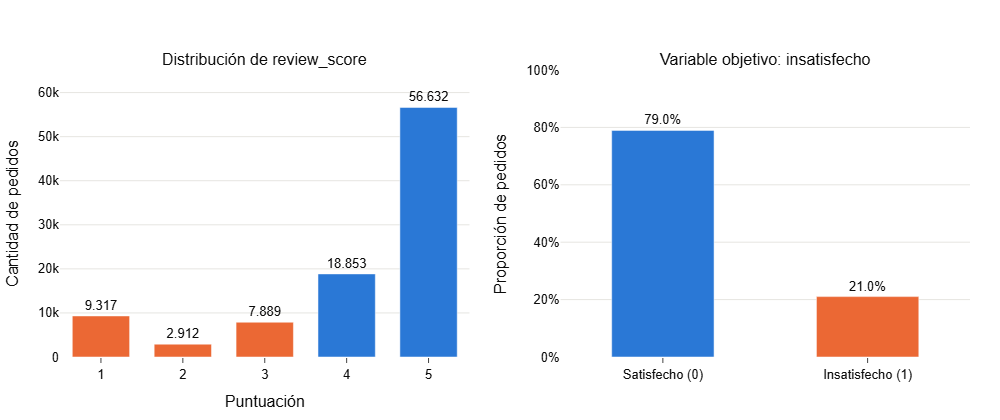

Razón de desbalance: 3.8 satisfechos por cada insatisfecho


In [4]:
conteo = df['review_score'].value_counts().sort_index()
prop = df[VAR_OBJETIVO].value_counts(normalize=True).sort_index()

fig = make_subplots(rows=1, cols=2,
                    subplot_titles=('Distribución de review_score', 'Variable objetivo: insatisfecho'))

# Izquierda: puntuación original, coloreada según la clase que genera
fig.add_trace(go.Bar(
    x=conteo.index, y=conteo.values,
    marker_color=[NARANJA if s <= 3 else AZUL for s in conteo.index],
    text=[f'{v:,}'.replace(',', '.') for v in conteo.values], textposition='outside',
    hovertemplate='Puntuación %{x}<br>%{y:,} pedidos<extra></extra>',
), row=1, col=1)

# Derecha: variable objetivo binaria
fig.add_trace(go.Bar(
    x=['Satisfecho (0)', 'Insatisfecho (1)'], y=prop.values, width=0.5,
    marker_color=[AZUL, NARANJA],
    text=[f'{v:.1%}' for v in prop.values], textposition='outside',
    hovertemplate='%{x}<br>%{y:.1%} de los pedidos<extra></extra>',
), row=1, col=2)

fig.update_xaxes(title_text='Puntuación', dtick=1, row=1, col=1)
fig.update_yaxes(title_text='Cantidad de pedidos', range=[0, conteo.max() * 1.15], row=1, col=1)
fig.update_yaxes(title_text='Proporción de pedidos', tickformat='.0%', range=[0, 1], row=1, col=2)
fig.update_layout(showlegend=False, height=420, width=1000, bargap=0.3)

guardar(fig, '03_01_variable_objetivo')
fig.show()

print(f'Razón de desbalance: {prop[0] / prop[1]:.1f} satisfechos por cada insatisfecho')

**Observaciones:**
- `review_score` es muy asimétrica: el 5 concentra el 59% de las reseñas.
- El 1 (9.317) es más frecuente que el 2 y el 3: los clientes insatisfechos tienden a los extremos.
- La variable objetivo está **desbalanceada: 79,0% satisfechos vs 21,0% insatisfechos** (≈ 3,8 a 1).
  Un modelo que prediga siempre "satisfecho" acertaría el 79% sin detectar a ningún insatisfecho:
  por eso la Accuracy no sirve como métrica y será necesario aplicar técnicas de balanceo.

## 4. Análisis univariado: variables numéricas
Para cada una de las 22 variables numéricas se analiza: medidas de resumen, asimetría y
outliers según la regla del rango intercuartílico (IQR):
- **Moderado:** fuera de [Q1 − 1,5·IQR ; Q3 + 1,5·IQR]
- **Extremo:** fuera de [Q1 − 3·IQR ; Q3 + 3·IQR]

Se reutilizan las funciones `resumen_numerico` y `tabla_outliers` de `src/utils.py` (Notebook 01).

In [5]:
resumen = resumen_numerico(df, VARS_NUMERICAS)
resumen['% nulos'] = df[VARS_NUMERICAS].isna().mean().mul(100).round(2)
resumen = resumen.join(tabla_outliers(df, VARS_NUMERICAS)[['% moderados', '% extremos']])

columnas = ['count', '% nulos', 'mean', '50%', 'std', 'min', '1%', '99%', 'max',
            'asimetría', '% moderados', '% extremos']
display(resumen[columnas].round(2))

,count,% nulos,mean,50%,std,min,1%,99%,max,asimetría,% moderados,% extremos
dias_entrega_observados,95603.0,0.00,11.74,10.16,7.00,0.53,1.82,32.88,70.21,1.12,2.59,0.14
dias_anticipacion,95603.0,0.00,11.98,11.98,7.90,0.00,0.00,35.14,146.02,1.04,2.12,0.21
dias_entrega_estimada,95603.0,0.00,23.72,23.22,8.75,2.01,6.06,50.14,155.14,0.90,2.50,0.26
horas_aprobacion,95589.0,0.01,10.27,0.34,20.53,0.00,0.00,89.75,741.44,4.43,9.27,3.81
dias_hasta_transportista,95603.0,0.00,3.19,2.20,3.38,-171.21,0.09,17.11,55.10,2.02,5.29,2.26
dias_despacho_vs_limite,95603.0,0.00,-3.38,-3.24,4.90,-1046.86,-12.84,7.02,45.87,-101.67,4.05,1.06
cant_items,95603.0,0.00,1.14,1.00,0.53,1.00,1.00,3.00,21.00,7.30,9.94,9.94
cant_productos,95603.0,0.00,1.04,1.00,0.23,1.00,1.00,2.00,8.00,8.11,3.29,3.29
cant_vendedores,95603.0,0.00,1.01,1.00,0.12,1.00,1.00,2.00,5.00,9.92,1.31,1.31
precio_total,95603.0,0.00,136.85,86.25,207.95,0.85,11.99,990.00,13440.00,9.76,7.93,4.07


### Distribuciones
Histogramas recortados entre el percentil 1 y el 99 para ver la forma de cada distribución
(las barras en los bordes acumulan los valores recortados). La línea punteada es la mediana.

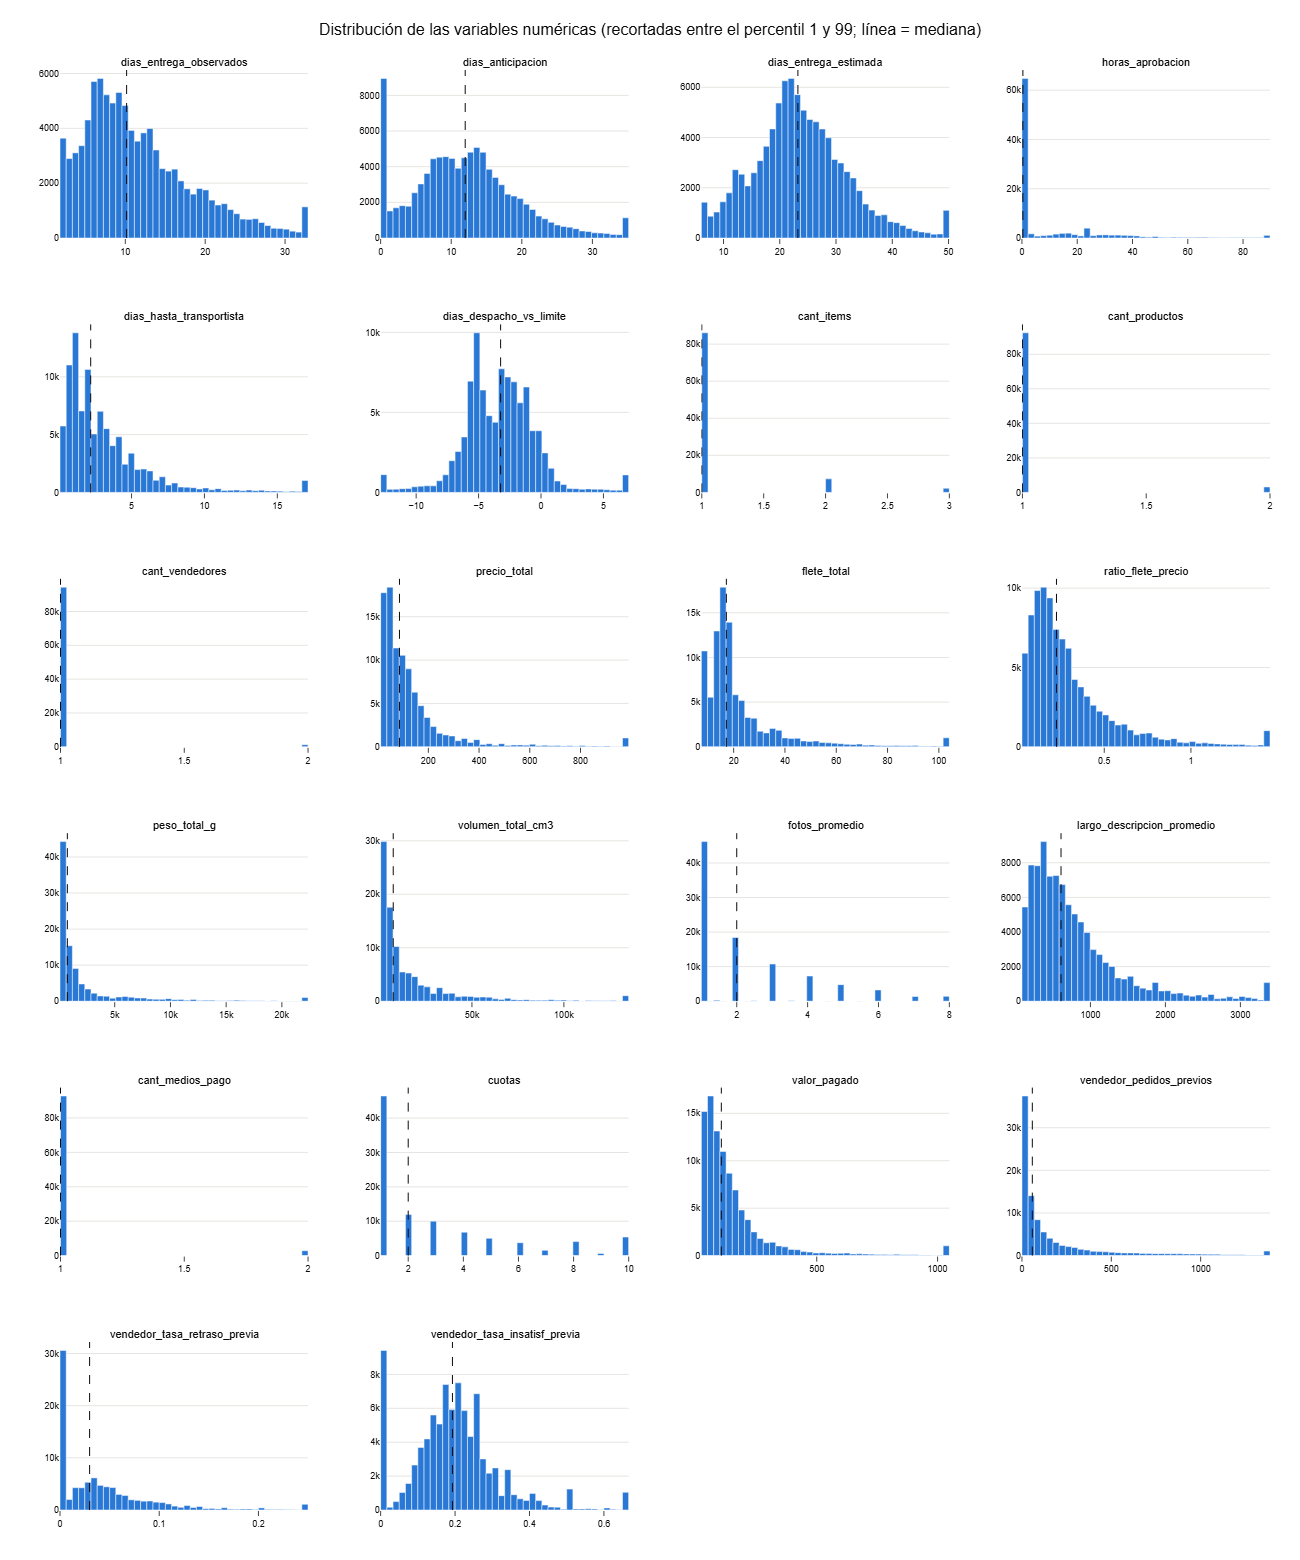

In [6]:
n = len(VARS_NUMERICAS)
ncols = 4
nrows = int(np.ceil(n / ncols))   # 22 variables en 4 columnas -> 6 filas

fig = make_subplots(rows=nrows, cols=ncols, subplot_titles=VARS_NUMERICAS,
                    vertical_spacing=0.06, horizontal_spacing=0.06)

for i, var in enumerate(VARS_NUMERICAS):
    fila, col = i // ncols + 1, i % ncols + 1      # posición en la grilla
    s = df[var].dropna()
    p1, p99 = s.quantile(0.01), s.quantile(0.99)

    # Se calculan las 40 barras ANTES de graficar: Plotly recibe 40 números, no 95.000
    conteos, bordes = np.histogram(s.clip(p1, p99), bins=40)
    centros = (bordes[:-1] + bordes[1:]) / 2

    fig.add_trace(go.Bar(
        x=centros, y=conteos, width=np.diff(bordes), marker_color=AZUL,
        marker_line=dict(color='white', width=0.5),
        customdata=np.stack([bordes[:-1], bordes[1:]], axis=1),
        hovertemplate=f'{var}<br>%{{customdata[0]:.2f}} a %{{customdata[1]:.2f}}'
                      f'<br>%{{y:,}} pedidos<extra></extra>',
    ), row=fila, col=col)
    fig.add_vline(x=s.median(), line_dash='dash', line_color='#0b0b0b', line_width=1,
                  row=fila, col=col)

fig.update_annotations(font_size=11)
fig.update_xaxes(tickfont_size=9)
fig.update_yaxes(tickfont_size=9)
fig.update_layout(height=260 * nrows, width=1300, showlegend=False,
                  title='Distribución de las variables numéricas '
                        '(recortadas entre el percentil 1 y 99; línea = mediana)')

guardar(fig, '03_02_numericas_distribucion')
fig.show()

**Observaciones:**
- **Tiempos:** la entrega observada tiene mediana de 10 días; el plazo prometido es de ~23 días,
  por lo que la mayoría de los pedidos llega mucho antes de lo prometido.
  `dias_anticipacion` tiene un pico en 0 que corresponde a los pedidos atrasados.
- **Aprobación del pago:** mediana de 0,3 horas (casi instantáneo), con una cola larga
  (asimetría 4,4) por los pagos que se acreditan con demora, como el boleto.
- **Montos y tamaño (precio, flete, valor pagado, peso, volumen):** muy asimétricos (asimetría entre
  6 y 12) y con 8–14% de outliers moderados. Son ventas reales, no errores, por lo que se conservan
  y se evaluará una transformación logarítmica.
- **Variables de conteo:** `cant_items`, `cant_productos`, `cant_vendedores` y `cant_medios_pago`
  valen 1 en más del 90% de los pedidos. Aun así, los pocos pedidos con más de un ítem o vendedor
  tienen mucha más insatisfacción (ver sección 6).
- **Valores inválidos:** `dias_hasta_transportista` (mínimo −171) y `dias_despacho_vs_limite`
  (mínimo −1.047) por errores de fechas; `peso_total_g`, `volumen_total_cm3` y `cuotas` con mínimo 0.
- **Nulos:** solo en el historial del vendedor (5–6%, vendedores sin historial previo) y en fotos y
  descripción (1,4%, productos sin ficha).

## 5. Análisis univariado: variables binarias y categóricas

In [7]:
binarias = pd.DataFrame({
    'pedidos con 1': df[VARS_BINARIAS].sum(),
    '% con 1': (df[VARS_BINARIAS].mean() * 100).round(1),
})
binarias['descripción'] = [DESCRIPCION[v] for v in binarias.index]
display(binarias)

,pedidos con 1,% con 1,descripción
entrega_tardia,6340,6.6,1 si el pedido llegó después del día estimado
despacho_tardio,8530,8.9,1 si el vendedor despachó después de su fecha límite
mismo_estado,34429,36.0,1 si cliente y vendedor principal están en el mismo estado
misma_region,59481,62.2,1 si cliente y vendedor principal están en la misma región


### Variables categóricas
Para cada variable: cantidad de categorías, la más frecuente y qué porcentaje de pedidos
concentran las 5 más frecuentes.

In [8]:
filas = []
for var in VARS_CATEGORICAS:
    frec = df[var].value_counts(normalize=True)     # proporción de cada categoría
    filas.append({
        'variable': var,
        'categorías': df[var].nunique(),
        '% nulos': round(df[var].isna().mean() * 100, 2),
        'más frecuente': frec.index[0],
        '% más frecuente': round(frec.iloc[0] * 100, 1),
        '% en las 5 más frecuentes': round(frec.head(5).sum() * 100, 1),
    })
display(pd.DataFrame(filas).set_index('variable'))

,categorías,% nulos,más frecuente,% más frecuente,% en las 5 más frecuentes
variable,,,,,
categoria_principal,74,0.0,cama_mesa_y_bano,9.5,39.3
tipo_pago,4,0.0,tarjeta_credito,75.5,100.0
customer_state,27,0.0,SP,42.1,77.2
customer_region,5,0.0,Sudeste,68.6,100.0
seller_state,22,0.0,SP,70.9,94.6
seller_region,5,0.0,Sudeste,83.5,100.0
mes_compra,12,0.0,8,11.0,51.5
dia_semana_compra,7,0.0,0,16.3,77.0


### Distribuciones

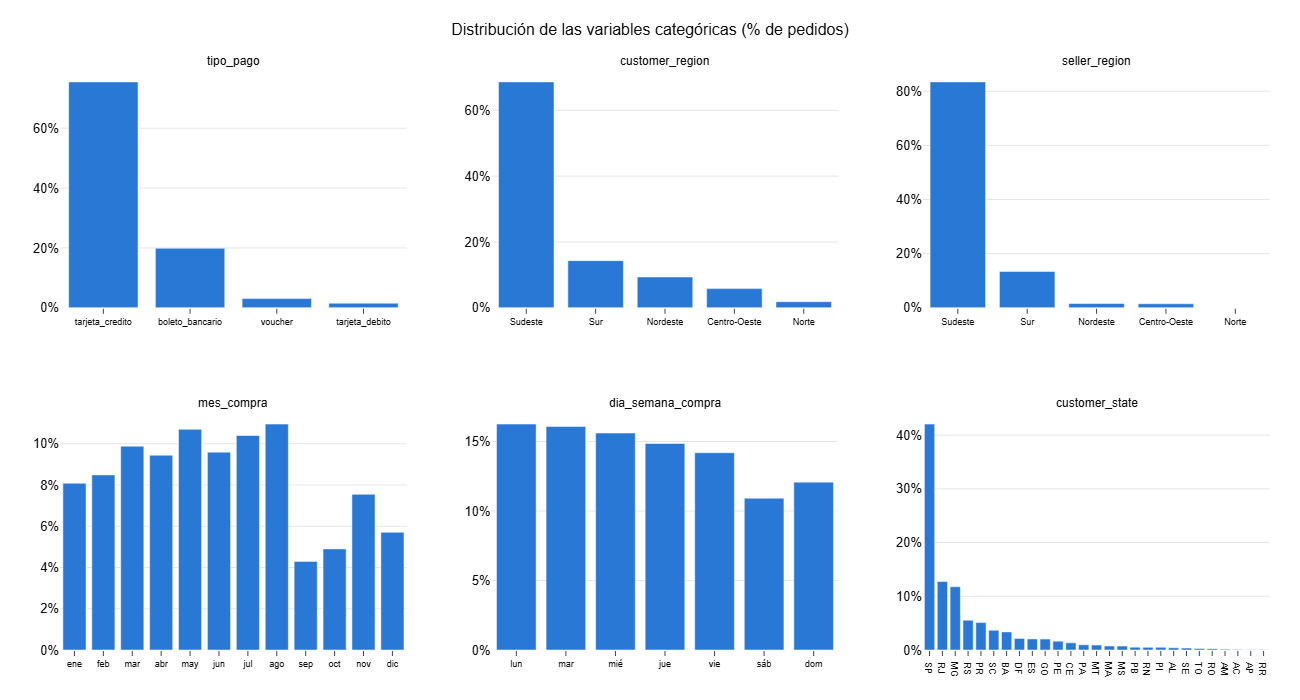

In [9]:
DIAS = {0: 'lun', 1: 'mar', 2: 'mié', 3: 'jue', 4: 'vie', 5: 'sáb', 6: 'dom'}
MESES = {1: 'ene', 2: 'feb', 3: 'mar', 4: 'abr', 5: 'may', 6: 'jun',
         7: 'jul', 8: 'ago', 9: 'sep', 10: 'oct', 11: 'nov', 12: 'dic'}

# (variable, etiquetas para mostrar, ¿ordenar por valor natural en vez de por frecuencia?)
graficos = [
    ('tipo_pago', None, False),
    ('customer_region', None, False),
    ('seller_region', None, False),
    ('mes_compra', MESES, True),
    ('dia_semana_compra', DIAS, True),
    ('customer_state', None, False),
]

fig = make_subplots(rows=2, cols=3, subplot_titles=[g[0] for g in graficos],
                    vertical_spacing=0.18, horizontal_spacing=0.07)

for i, (var, etiquetas, orden_natural) in enumerate(graficos):
    frec = df[var].value_counts(normalize=True)   # ya resumido: pocas barras, liviano
    if orden_natural:
        frec = frec.sort_index()                  # meses y días en orden calendario
    if etiquetas:
        frec = frec.rename(index=etiquetas)
    fig.add_trace(go.Bar(
        x=frec.index.astype(str), y=frec.values, marker_color=AZUL,
        hovertemplate='%{x}<br>%{y:.1%} de los pedidos<extra></extra>',
    ), row=i // 3 + 1, col=i % 3 + 1)

fig.update_yaxes(tickformat='.0%')
fig.update_xaxes(tickfont_size=9)
fig.update_annotations(font_size=12)
fig.update_layout(height=700, width=1300, showlegend=False,
                  title='Distribución de las variables categóricas (% de pedidos)')

guardar(fig, '03_03_categoricas_distribucion')
fig.show()

**Observaciones:**
- **Binarias:** solo el 6,6% de los pedidos llega atrasado y el 8,9% tiene despacho tardío del vendedor.
  El 36% de los pedidos se compra a un vendedor del mismo estado y el 62% de la misma región.
- **Medio de pago:** la tarjeta de crédito domina (75,5%), seguida del boleto (~20%).
- **Ubicación:** fuerte concentración en el Sudeste: 68,6% de los clientes y 83,5% de los vendedores.
  São Paulo concentra el 42% de los clientes y el 71% de los vendedores. Varios estados tienen muy
  pocos pedidos, por lo que la región resume mejor la ubicación que el estado.
- **Categoría del producto:** muy dispersa: 74 categorías, la más frecuente (cama, mesa y baño) tiene
  solo el 9,5% y 59 categorías suman apenas el 21%. Agrupar las poco frecuentes simplificará el modelo.
- **Mes de compra:** la caída de septiembre a diciembre no es estacional: el dataset cubre de
  septiembre de 2016 a agosto de 2018, por lo que esos meses tienen datos de un solo año y el resto
  de dos. Hay que tener cuidado al usar esta variable.
- **Día de la semana:** menos compras el fin de semana, pero diferencias moderadas.

## 6. Relación de cada predictora con la insatisfacción
Para cada variable se compara el **% de insatisfechos** entre sus grupos o tramos.
Si una variable no tuviera relación con la insatisfacción, todos los grupos estarían cerca del
promedio general (21%, línea punteada). Cuanto más se alejan, más útil es la variable para el modelo.

cantidad de pedidos  % de pedidos  % insatisfechos
variable        valor                                                    
entrega_tardia  no                   89263          93.4             17.3
                sí                    6340           6.6             73.5
despacho_tardio no                   87073          91.1             19.8
                sí                    8530           8.9             34.0
mismo_estado    no                   61174          64.0             22.7
                sí                   34429          36.0             18.1
misma_region    no                   36122          37.8             22.4
                sí                   59481          62.2             20.2

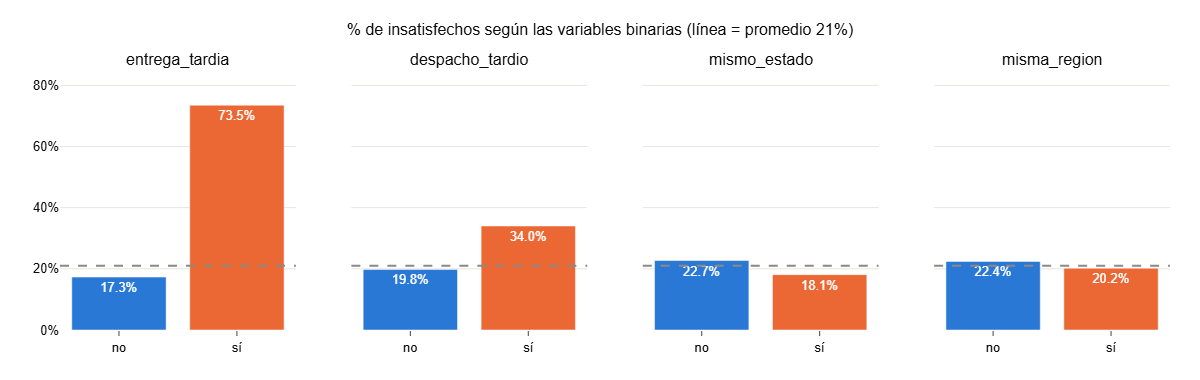

In [17]:
TASA_GLOBAL = df[VAR_OBJETIVO].mean()
GRIS = '#8a8984'
si_no = {0: 'no', 1: 'sí'}

# Tabla: una fila por variable y valor
tablas = []
for var in VARS_BINARIAS:
    t = tasa_insatisfaccion(df, var, si_no)
    t.index = pd.MultiIndex.from_product([[var], t.index], names=['variable', 'valor'])
    tablas.append(t)
display(pd.concat(tablas))

# Gráfico: % de insatisfechos en cada grupo
fig = make_subplots(rows=1, cols=4, subplot_titles=VARS_BINARIAS, shared_yaxes=True)
for i, var in enumerate(VARS_BINARIAS):
    t = tasa_insatisfaccion(df, var, si_no)
    fig.add_trace(go.Bar(
        x=t.index, y=t['% insatisfechos'] / 100, marker_color=[AZUL, NARANJA],
        text=[f'{v:.1f}%' for v in t['% insatisfechos']],
        textposition='inside', insidetextanchor='end', textfont=dict(color='white', size=13),
        hovertemplate='%{x}<br>%{y:.1%} insatisfechos<extra></extra>',
    ), row=1, col=i + 1)

fig.add_hline(y=TASA_GLOBAL, line_dash='dash', line_color=GRIS)
fig.update_yaxes(tickformat='.0%', range=[0, 0.85])
fig.update_layout(height=380, width=1200, showlegend=False,
                  title=f'% de insatisfechos según las variables binarias (línea = promedio {TASA_GLOBAL:.0%})')

guardar(fig, '03_05_binarias_vs_insatisfaccion')
fig.show()

In [15]:
# En estas variables casi todos los pedidos valen 1: se compara "1" contra "más de 1"
VARS_CONTEO = ['cant_items', 'cant_productos', 'cant_vendedores', 'cant_medios_pago']

tablas = []
for var in VARS_CONTEO:
    grupo = np.where(df[var] > 1, 'más de 1', '1')
    t = tasa_insatisfaccion(df.assign(grupo=grupo), 'grupo')
    t.index = pd.MultiIndex.from_product([[var], t.index], names=['variable', 'valor'])
    tablas.append(t)
display(pd.concat(tablas))

cantidad de pedidos  % de pedidos  % insatisfechos
variable         valor                                                       
cant_items       1                       86100          90.1             19.4
                 más de 1                 9503           9.9             36.2
cant_productos   1                       92455          96.7             20.2
                 más de 1                 3148           3.3             44.8
cant_vendedores  1                       94347          98.7             20.5
                 más de 1                 1256           1.3             60.7
cant_medios_pago 1                       92756          97.0             21.0
                 más de 1                 2847           3.0             22.5

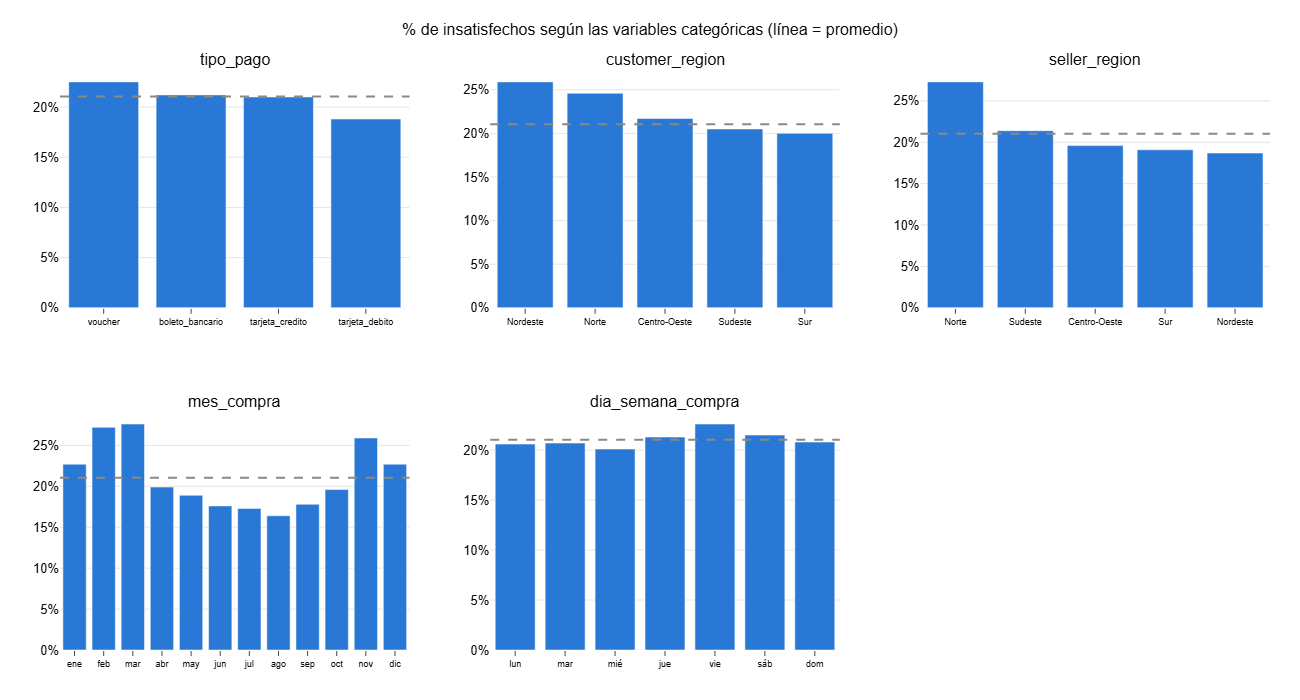

In [11]:
DIAS = {0: 'lun', 1: 'mar', 2: 'mié', 3: 'jue', 4: 'vie', 5: 'sáb', 6: 'dom'}
MESES = {1: 'ene', 2: 'feb', 3: 'mar', 4: 'abr', 5: 'may', 6: 'jun',
         7: 'jul', 8: 'ago', 9: 'sep', 10: 'oct', 11: 'nov', 12: 'dic'}

# (variable, etiquetas, ¿orden calendario?)
graficos = [
    ('tipo_pago', None, False),
    ('customer_region', None, False),
    ('seller_region', None, False),
    ('mes_compra', MESES, True),
    ('dia_semana_compra', DIAS, True),
]

fig = make_subplots(rows=2, cols=3, subplot_titles=[g[0] for g in graficos], vertical_spacing=0.18)
for i, (var, etiquetas, orden_calendario) in enumerate(graficos):
    t = tasa_insatisfaccion(df, var, etiquetas)
    if not orden_calendario:
        t = t.sort_values('% insatisfechos', ascending=False)
    fig.add_trace(go.Bar(
        x=t.index.astype(str), y=t['% insatisfechos'] / 100, marker_color=AZUL,
        customdata=t['cantidad de pedidos'],
        hovertemplate='%{x}<br>%{y:.1%} insatisfechos<br>%{customdata:,} pedidos<extra></extra>',
    ), row=i // 3 + 1, col=i % 3 + 1)

fig.add_hline(y=TASA_GLOBAL, line_dash='dash', line_color=GRIS)
fig.update_yaxes(tickformat='.0%', rangemode='tozero')
fig.update_xaxes(tickfont_size=9)
fig.update_layout(height=700, width=1300, showlegend=False,
                  title='% de insatisfechos según las variables categóricas (línea = promedio)')
guardar(fig, '03_06_categoricas_vs_insatisfaccion')
fig.show()

Categorías con al menos 500 pedidos: 26 de 74


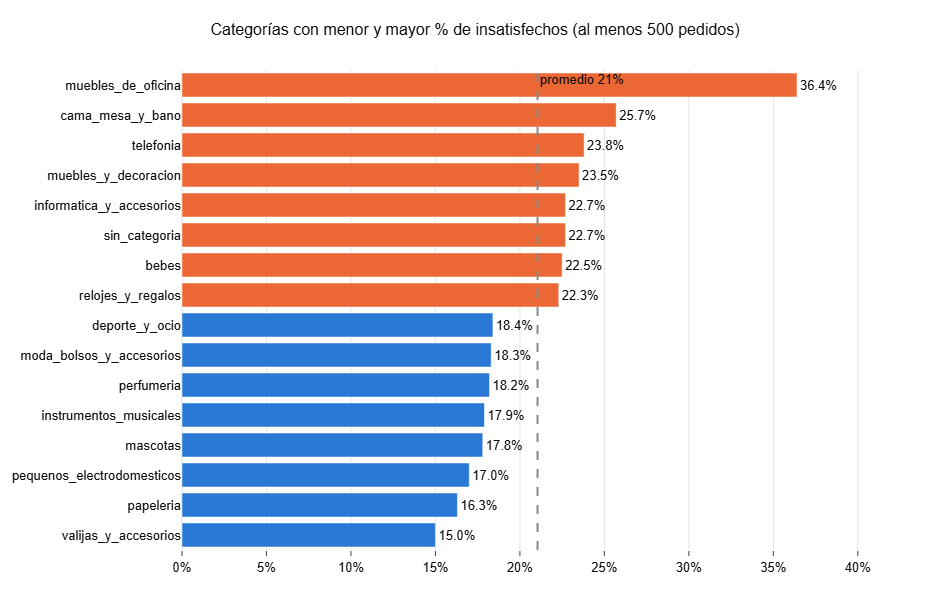

In [12]:
# Solo categorías con al menos 500 pedidos: con pocos pedidos el porcentaje no es confiable
MIN_PEDIDOS = 500
t = tasa_insatisfaccion(df, 'categoria_principal')
t = t[t['cantidad de pedidos'] >= MIN_PEDIDOS].sort_values('% insatisfechos')
print(f'Categorías con al menos {MIN_PEDIDOS} pedidos: {len(t)} de {df["categoria_principal"].nunique()}')

extremos = pd.concat([t.head(8), t.tail(8)])     # las 8 con menos y las 8 con más insatisfacción

fig = go.Figure(go.Bar(
    x=extremos['% insatisfechos'] / 100, y=extremos.index, orientation='h',
    marker_color=[AZUL] * 8 + [NARANJA] * 8,
    text=[f'{v:.1f}%' for v in extremos['% insatisfechos']], textposition='outside',
    customdata=extremos['cantidad de pedidos'],
    hovertemplate='%{y}<br>%{x:.1%} insatisfechos<br>%{customdata:,} pedidos<extra></extra>',
))
fig.add_vline(x=TASA_GLOBAL, line_dash='dash', line_color=GRIS,
              annotation_text=f'promedio {TASA_GLOBAL:.0%}')
fig.update_xaxes(tickformat='.0%', showgrid=True, gridcolor='#e6e5e1',
                 range=[0, extremos['% insatisfechos'].max() / 100 * 1.2])
fig.update_yaxes(showgrid=False)
fig.update_layout(height=600, width=950,
                  title=f'Categorías con menor y mayor % de insatisfechos (al menos {MIN_PEDIDOS} pedidos)')
guardar(fig, '03_07_categoria_vs_insatisfaccion')
fig.show()

### Variables numéricas
Dos miradas: la mediana de cada variable en satisfechos e insatisfechos, y el % de insatisfechos
por **quintil**: se ordenan los pedidos de menor a mayor y se dividen en 5 grupos de igual tamaño
(T1 = 20% con valores más bajos … T5 = 20% con valores más altos).

In [13]:
medianas = df.groupby(VAR_OBJETIVO)[VARS_NUMERICAS].median().T
medianas.columns = ['mediana satisfechos', 'mediana insatisfechos']
medianas['diferencia %'] = ((medianas['mediana insatisfechos'] / medianas['mediana satisfechos'] - 1) * 100).round(1)
display(medianas.round(2))

,mediana satisfechos,mediana insatisfechos,diferencia %
dias_entrega_observados,9.57,13.42,40.1
dias_anticipacion,12.24,8.63,-29.5
dias_entrega_estimada,23.11,23.63,2.3
horas_aprobacion,0.34,0.35,3.9
dias_hasta_transportista,2.12,2.78,31.2
dias_despacho_vs_limite,-3.32,-2.96,-10.9
cant_items,1.00,1.00,0.0
cant_productos,1.00,1.00,0.0
cant_vendedores,1.00,1.00,0.0
precio_total,84.90,89.96,6.0


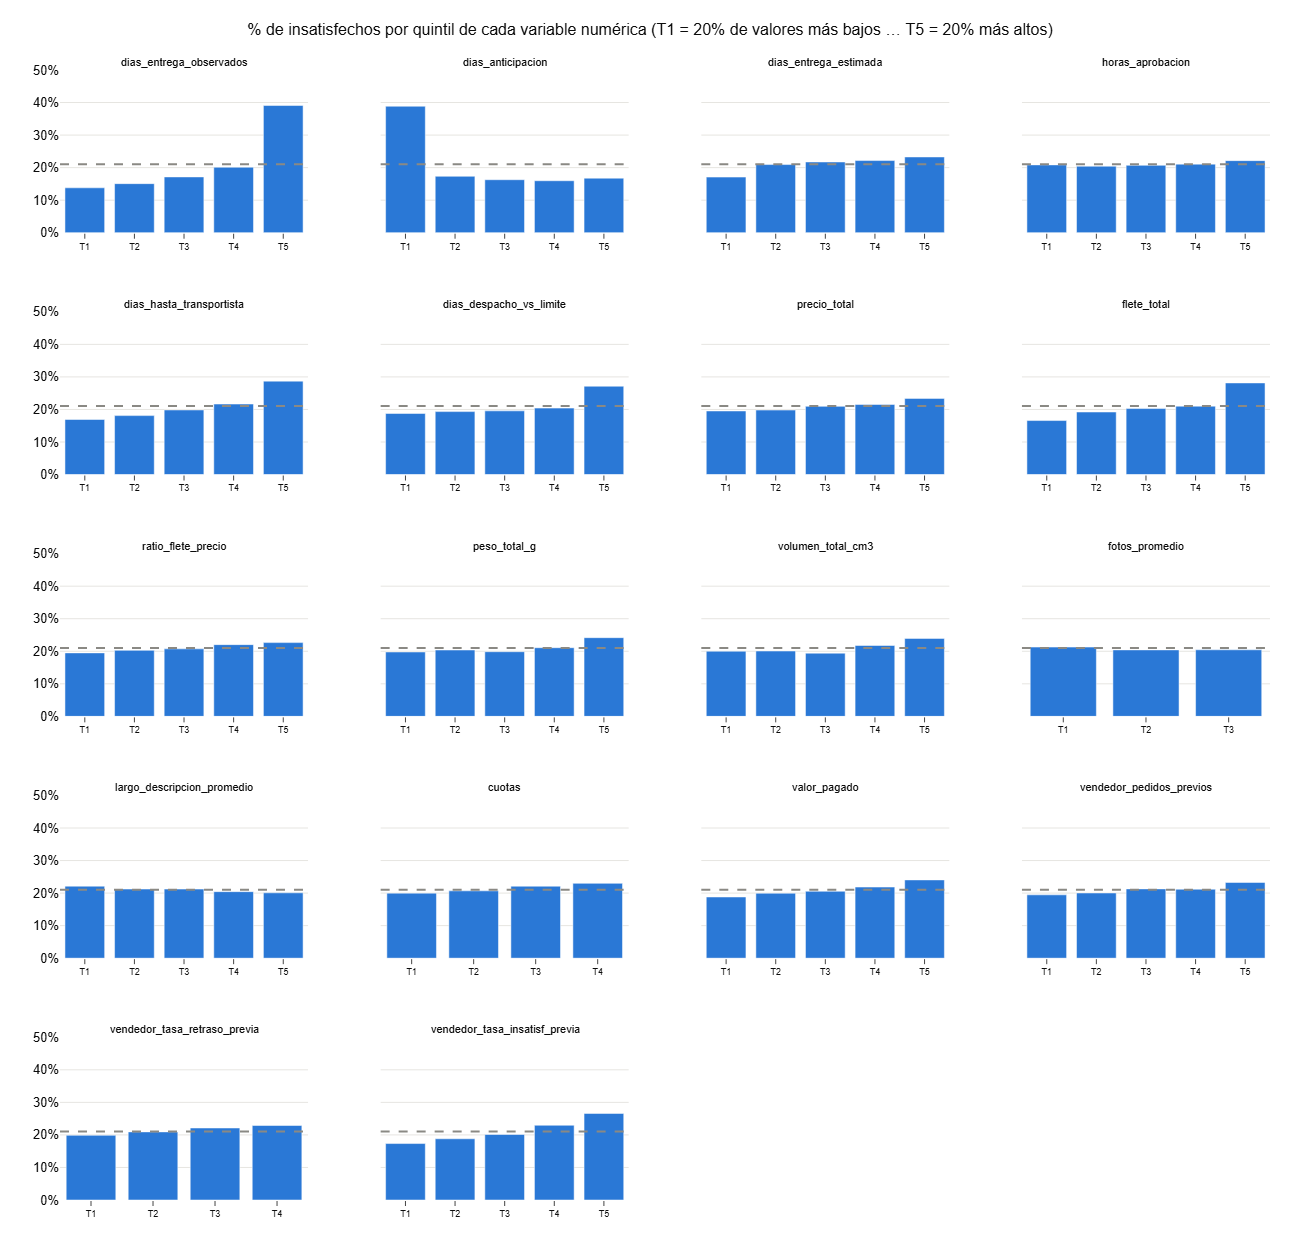

In [16]:
VARS_CONTINUAS = [v for v in VARS_NUMERICAS if v not in VARS_CONTEO]   # las de conteo ya se vieron

n = len(VARS_CONTINUAS)
ncols = 4
nrows = int(np.ceil(n / ncols))

fig = make_subplots(rows=nrows, cols=ncols, subplot_titles=VARS_CONTINUAS,
                    vertical_spacing=0.07, horizontal_spacing=0.06, shared_yaxes=True)

for i, var in enumerate(VARS_CONTINUAS):
    # duplicates='drop': si muchos valores se repiten (ej.: cuotas = 1) quedan menos de 5 tramos
    tramos = pd.qcut(df[var], q=5, duplicates='drop')
    t = df.groupby(tramos, observed=True)[VAR_OBJETIVO].agg(['mean', 'size'])
    rangos = [f'{iv.left:.3g} a {iv.right:.3g}' for iv in t.index]

    fig.add_trace(go.Bar(
        x=[f'T{j + 1}' for j in range(len(t))], y=t['mean'], marker_color=AZUL,
        customdata=np.stack([rangos, t['size']], axis=1),
        hovertemplate=f'{var}<br>%{{customdata[0]}}<br>%{{y:.1%}} insatisfechos'
                      f'<br>%{{customdata[1]:,}} pedidos<extra></extra>',
    ), row=i // ncols + 1, col=i % ncols + 1)

fig.add_hline(y=TASA_GLOBAL, line_dash='dash', line_color=GRIS)
fig.update_yaxes(tickformat='.0%', range=[0, 0.5])
fig.update_annotations(font_size=11)
fig.update_xaxes(tickfont_size=9)
fig.update_layout(height=250 * nrows, width=1300, showlegend=False,
                  title='% de insatisfechos por quintil de cada variable numérica '
                        '(T1 = 20% de valores más bajos … T5 = 20% más altos)')
guardar(fig, '03_08_numericas_vs_insatisfaccion')
fig.show()

**Observaciones:**
- **Entrega atrasada** es la variable más fuerte: 73,5% de insatisfechos vs 17,3% a tiempo.
  En la misma línea, los pedidos con más días de entrega (T5: 39%) y los que llegan sin anticipación
  respecto de la fecha prometida (T1 de `dias_anticipacion`: 39%) duplican el promedio.
- **Despacho tardío del vendedor:** 34,0% vs 19,8%, y la demora hasta el transportista también
  aumenta la insatisfacción (T5: 29%).
- **Pedidos complejos:** con más de un vendedor la insatisfacción llega al 60,7%, con más de un
  producto distinto al 44,8% y con más de un ítem al 36,2%. Pocos pedidos, pero muy afectados.
- **Historial del vendedor:** la insatisfacción sube de forma escalonada con la insatisfacción previa
  del vendedor (de 17% en T1 a 27% en T5).
- **Ubicación:** comprar a un vendedor del mismo estado reduce la insatisfacción (18,1% vs 22,7%);
  los clientes del Nordeste y Norte están por encima del promedio (25,9% y 24,6%).
- **Categoría:** de 15% (valijas) a 36% (muebles de oficina) entre las categorías con al menos 500 pedidos.
- **Mes de compra:** febrero y marzo superan el 27%, mientras que de mayo a septiembre rondan el 17%.
- **Poca relación:** medio de pago, día de la semana, horas de aprobación, fotos, largo de la
  descripción y cantidad de medios de pago se mantienen cerca del promedio.